# 1. Environment Setup

Configure the necessary environment, install Qiskit, and verify dependencies.

In [39]:
!pip install qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from IPython.display import display

In [47]:
!pip install -q pylatexenc

In [48]:
import pylatexenc

print(pylatexenc.__version__)

2.11


## Basic Quantum Circuit Creation

Let's start by creating and displaying a simple 2-qubit quantum circuit.

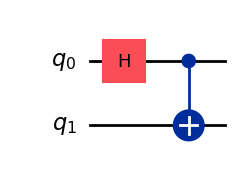

In [1]:
from qiskit import QuantumCircuit
from IPython.display import display
import qiskit.visualization

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
display(qc.draw(output="mpl"))

## 2. Using `compose()`

The `compose()` method allows us to combine two quantum circuits by appending one to the other.

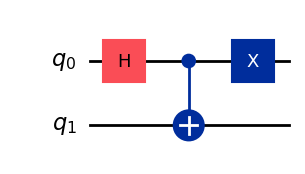

In [2]:
qc1=QuantumCircuit(2)
qc1.h(0)
qc1.cx(0,1)
qc2=QuantumCircuit(1)
qc2.x(0)
qc1.compose(qc2,inplace=True)
display(qc1.draw(output="mpl"))


## 3. Inverse Operations with `inverse()`

Finding the inverse of an operator or circuit is a key operation. For any unitary $U$:

$$U^\dagger U = I$$

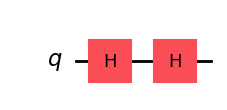

In [3]:
qc=QuantumCircuit(1)
qc.h(0)
inverse=qc.inverse()
final=qc.compose(inverse)
display(final.draw(output="mpl"))

## 4. Converting Circuits with `to_gate()`

You can package a whole `QuantumCircuit` into a single custom unitary gate using `.to_gate()`.

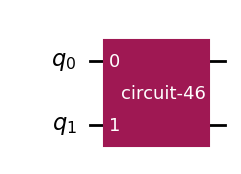

In [4]:
qc=QuantumCircuit(2)
qc.h(0)
qc.cx(0,1)
qc.x(1)
gate=qc.to_gate()
main_gate=QuantumCircuit(2)
main_gate.append(gate,[0,1])
display(main_gate.draw(output="mpl"))

## 5. Adding Subcircuits with `append()`

The `append()` method lets you add an instruction, gate, or subcircuit to specific target qubits in your main circuit.

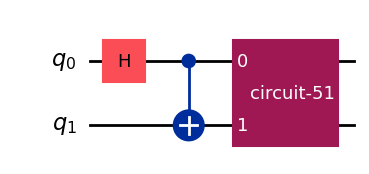

In [5]:
gate_1=QuantumCircuit(2)
gate_1.h(0)
gate_1.cx(0,1)
gate_2=QuantumCircuit(2)
gate_1.append(gate_2,[0,1])
display(gate_1.draw(output="mpl"))

### Exercise 1: Inverse of a 1-Qubit Circuit

* **Task:** Create a 1-qubit circuit with $H$ and $X$ gates, find its inverse, and compose them together.

<details>
<summary>💡 Click here for a hint</summary>

Create a `QuantumCircuit(1)`, add `.h(0)` and `.x(0)`. Call `.inverse()`, then use `.compose()` to verify they undo each other.
</details>

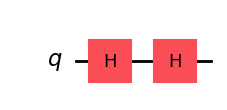

In [6]:
qc=QuantumCircuit(1)
qc.h(0)
inv=qc.inverse()
final_circuit=qc.compose(inv)
display(final_circuit.draw(output="mpl"))

### Exercise 2: Composing Two-Qubit Circuits

* **Task:** Create two separate 2-qubit circuits.
  * First circuit: Applies an $H$ gate on qubit 0.
  * Second circuit: Applies a $CNOT$ ($CX$) gate.
  * Combine them together using `.compose()`.

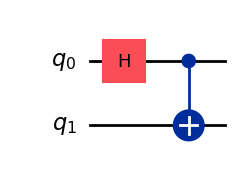

In [7]:
qc1=QuantumCircuit(2)
qc1.h(0)
qc2=QuantumCircuit(2)
qc2.cx(0,1)
qc1.compose(qc2,inplace=True)
display(qc1.draw(output="mpl"))

### Exercise 3: Creating a Custom Gate

* **Task:** Create a circuit containing an $H$ and a $CNOT$ gate, then convert it into a custom gate using `.to_gate()` and append it to a new circuit.

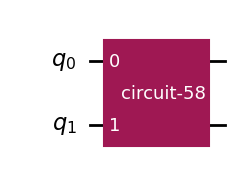

In [8]:
qc=QuantumCircuit(2)
qc.h(0)
qc.cx(0,1)
gate=qc.to_gate()
main_gate=QuantumCircuit(2)
main_gate.append(gate,[0,1])
display(main_gate.draw(output="mpl"))

### Exercise 4: Reusing a Bell-State Subcircuit

* **Task:** Build a custom 2-qubit Bell-state subcircuit and reuse it multiple times within a 4-qubit circuit.

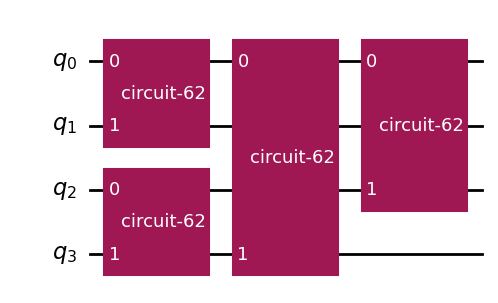

In [9]:
bell=QuantumCircuit(2)
qc.h(0)
qc.cx(0,1)
gate=bell.to_gate()
main_circuit=QuantumCircuit(4)
main_circuit.append(gate,[0,1])
main_circuit.append(gate,[2,3])
main_circuit.append(gate,[0,3])
main_circuit.append(gate,[0,2])
display(main_circuit.draw(output="mpl"))